# 1. CARGA DE DATOS Y LIMPIEZA INICIAL
Carga el archivo CSV con la matriz de datos urbanos y espaciales de Bogotá, mostrando una vista previa de su estructura.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

In [2]:
# Cargamos la matriz final resultante del proceso ETL
df = pd.read_csv('../data/matriz_barrios_unificada.csv')

# Eliminamos los registros que no tienen valor de referencia para 2026 (nuestra variable objetivo)
df_clean = df.dropna(subset=['v_ref_2026']).copy()

In [3]:
df_clean.head()

,localidad,barrio,estrato_predominante,area_km2,v_ref_2015,v_ref_2025,v_ref_2026,cagr_15_25,num_estaciones_transmilenio,num_listings_airbnb,densidad_airbnb_km2,geometry
0,USME,EL BOSQUE,1.0,0.055879,290000.0,650000.0,660000.0,0.084056,0,0.0,0.000000,POLYGON ((-74.10014659299998 4.505445796000060...
1,SUBA,BILBAO,2.0,0.295314,750000.0,1790000.0,2050000.0,0.090886,0,0.0,0.000000,"POLYGON ((-74.113150507 4.751871279999989, -74..."
2,KENNEDY,CIUDAD KENNEDY CENTRAL,3.0,0.476473,1000000.0,2900000.0,2640000.0,0.112346,0,7.0,14.691286,POLYGON ((-74.15600688799998 4.616521243000022...
3,CHAPINERO,CONCEPCION NORTE,3.0,0.140259,1400000.0,3580000.0,4380000.0,0.098438,1,0.0,0.000000,POLYGON ((-74.06568096400002 4.656363177999992...
4,PUENTE ARANDA,COLON,3.0,0.285947,1300000.0,2850000.0,3170000.0,0.081658,0,16.0,55.954334,POLYGON ((-74.11963554699997 4.619638797999983...


In [4]:
print(f"Registros originales: {len(df)} | Registros tras filtrar nans en v_ref_2026: {len(df_clean)}")

Registros originales: 1098 | Registros tras filtrar nans en v_ref_2026: 1090


# 2. TRANSFORMACIONES LOGARÍTMICAS

In [5]:
# Aplicamos logaritmo natural al precio para estabilizar la varianza (heterocedasticidad)
df_clean['log_v_ref_2026'] = np.log(df_clean['v_ref_2026'])

# Aplicamos log1p (logaritmo de x + 1) a la densidad porque tiene valores en 0
df_clean['log_densidad_airbnb'] = np.log1p(df_clean['densidad_airbnb_km2'])

# 3. TRATAMIENTO DE DATOS ATÍPICOS (Rango Intercuartílico - IQR)

In [6]:
# Calculamos los límites para aislar los barrios con precios extremadamente altos o bajos
Q1 = df_clean['log_v_ref_2026'].quantile(0.25)
Q3 = df_clean['log_v_ref_2026'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtramos la base para mantener solo los datos dentro de una distribución normal
df_model = df_clean[(df_clean['log_v_ref_2026'] >= limite_inferior) & 
                    (df_clean['log_v_ref_2026'] <= limite_superior)].copy()

print(f"Registros originales (sin NaNs): {len(df_clean)} | Registros tras filtrar atípicos: {len(df_model)}")

Registros originales (sin NaNs): 1090 | Registros tras filtrar atípicos: 1058


# 4. PREPARACIÓN DE VARIABLES Y PARTICIÓN (TRAIN/TEST)
Divide la matriz supervisada en conjuntos de entrenamiento (80%) y prueba (20%) para evaluar de manera objetiva el rendimiento del modelo.

In [7]:
# Definimos las variables predictoras (X) y la variable objetivo (y)
variables_predictoras = [
    'log_densidad_airbnb',          # Efecto turístico transformado
    'estrato_predominante',         # Control socioeconómico
    'num_estaciones_transmilenio',  # Control de conectividad
    'cagr_15_25'                    # Inercia histórica del mercado
]

X = df_model[variables_predictoras]
y = df_model['log_v_ref_2026']

# Dividimos en 80% entrenamiento y 20% prueba (fijando semilla para reproducibilidad)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. ENTRENAMIENTO Y EVALUACIÓN CON XGBOOST REGRESSOR

In [9]:
# 1. Configuración del modelo con hiperparámetros robustos para evitar overfitting
modelo_xgb = xgb.XGBRegressor(
    n_estimators=300,        # Número de árboles
    learning_rate=0.05,      # Tasa de aprendizaje (conservadora para mayor precisión)
    max_depth=5,             # Profundidad máxima de cada árbol
    subsample=0.8,           # Usa el 80% de los datos por árbol (previene overfitting)
    colsample_bytree=0.8,    # Usa el 80% de las variables por árbol
    random_state=42,
    objective='reg:squarederror'
)

# 2. Entrenamiento del modelo
modelo_xgb.fit(X_train, y_train)

# 3. Predicciones en la base de prueba
y_pred_xgb_log = modelo_xgb.predict(X_test)

# 4. Revertir la transformación logarítmica (a Pesos Colombianos reales)
y_pred_xgb_real = np.exp(y_pred_xgb_log)
y_test_real = np.exp(y_test)

# 5. Cálculo de métricas
r2_xgb_test = r2_score(y_test, y_pred_xgb_log)
mae_xgb_real = mean_absolute_error(y_test_real, y_pred_xgb_real)
rmse_xgb_real = np.sqrt(mean_squared_error(y_test_real, y_pred_xgb_real))

print("================ RESULTADOS XGBOOST REGRESSOR ================")
print(f"R-cuadrado en Test: {r2_xgb_test:.4f}")
print(f"Error Absoluto Medio (MAE): ${mae_xgb_real:,.0f} COP/m²")
print(f"Raíz del Error Cuadrático Medio (RMSE): ${rmse_xgb_real:,.0f} COP/m²")
print("==============================================================")

================ RESULTADOS XGBOOST REGRESSOR ================
R-cuadrado en Test: 0.5828
Error Absoluto Medio (MAE): $831,837 COP/m²
Raíz del Error Cuadrático Medio (RMSE): $1,481,995 COP/m²


# 6. IMPORTANCIA DE LAS VARIABLES (FEATURE IMPORTANCE)

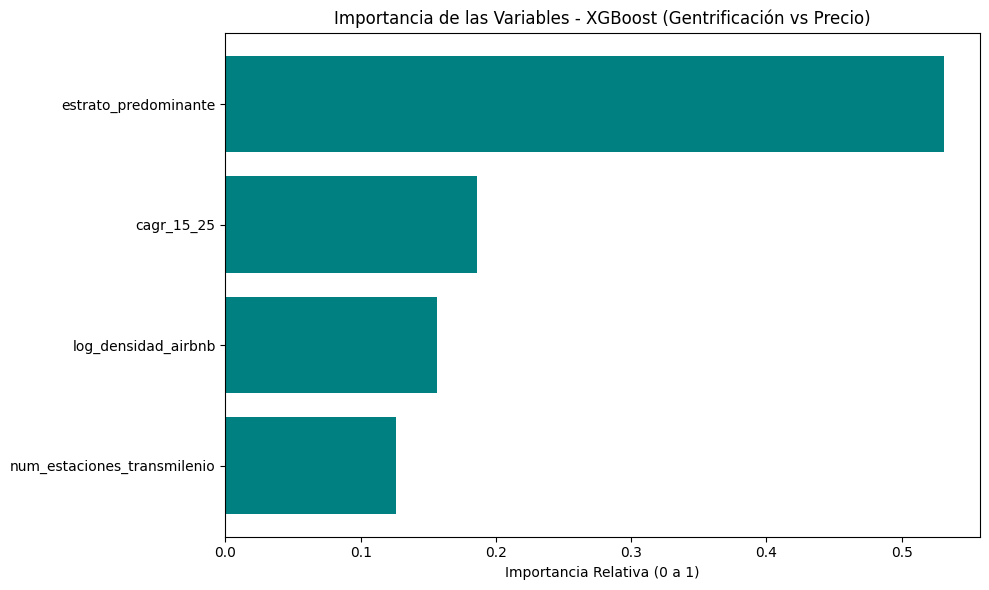

In [11]:
# Extraemos cuánto peso le dio el modelo a cada variable para hacer sus predicciones
importancias = modelo_xgb.feature_importances_
variables = X_train.columns

# Ordenar para graficar
indices = np.argsort(importancias)

plt.figure(figsize=(10, 6))
plt.title("Importancia de las Variables - XGBoost (Gentrificación vs Precio)")
plt.barh(range(len(indices)), importancias[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [variables[i] for i in indices])
plt.xlabel("Importancia Relativa (0 a 1)")
plt.tight_layout()
plt.show()